Question 1: Comparing Removal and Capping in Employee Data

An HR analytics team wants to analyze employee salaries. Some employees have exceptionally high salaries that may affect statistical analysis.

import pandas as pd

df = pd.DataFrame({
    "Employee_ID": range(1, 11),
    "Age": [22, 25, 28, 30, 32, 35, 38, 40, 42, 100],
    "Salary": [25000, 28000, 30000, 32000, 35000,
               38000, 42000, 45000, 50000, 500000]
})
A. Use the IQR method separately on Age and Salary to identify outliers. Create two datasets: one with outlier rows removed and another with outlier values capped at the calculated IQR boundaries. Display the lower and upper bounds for each feature.



In [1]:
import pandas as pd

df = pd.DataFrame({
    "Employee_ID": range(1, 11),
    "Age": [22, 25, 28, 30, 32, 35, 38, 40, 42, 100],
    "Salary": [25000, 28000, 30000, 32000, 35000,
               38000, 42000, 45000, 50000, 500000]
})

bounds = {}

for col in ["Age", "Salary"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    bounds[col] = (lower, upper)

    print(f"\n{col}")
    print("Q1 =", Q1)
    print("Q3 =", Q3)
    print("IQR =", IQR)
    print("Lower Bound =", lower)
    print("Upper Bound =", upper)

outlier_mask = pd.Series(False, index=df.index)

for col in ["Age", "Salary"]:
    lower, upper = bounds[col]

    mask = (df[col] < lower) | (df[col] > upper)
    outlier_mask = outlier_mask | mask

print("\nOutlier Records:")
print(df.loc[outlier_mask].to_string(index=False))

removed_df = df.loc[~outlier_mask].copy()

capped_df = df.copy()

for col in ["Age", "Salary"]:
    lower, upper = bounds[col]
    capped_df[col] = capped_df[col].clip(lower, upper)

print("\nDataset After Removal:")
print(removed_df.to_string(index=False))

print("\nDataset After Capping:")
print(capped_df.to_string(index=False))



Age
Q1 = 28.5
Q3 = 39.5
IQR = 11.0
Lower Bound = 12.0
Upper Bound = 56.0

Salary
Q1 = 30500.0
Q3 = 44250.0
IQR = 13750.0
Lower Bound = 9875.0
Upper Bound = 64875.0

Outlier Records:
 Employee_ID  Age  Salary
          10  100  500000

Dataset After Removal:
 Employee_ID  Age  Salary
           1   22   25000
           2   25   28000
           3   28   30000
           4   30   32000
           5   32   35000
           6   35   38000
           7   38   42000
           8   40   45000
           9   42   50000

Dataset After Capping:
 Employee_ID  Age  Salary
           1   22   25000
           2   25   28000
           3   28   30000
           4   30   32000
           5   32   35000
           6   35   38000
           7   38   42000
           8   40   45000
           9   42   50000
          10   56   64875


B. Compare the original, removed, and capped datasets using row counts, means, medians, and standard deviations. Explain why removal and capping produce different statistical results and identify the limitations of each approach.

In [2]:
import pandas as pd
df = pd.DataFrame({
    "Employee_ID": range(1, 11),
    "Age": [22, 25, 28, 30, 32, 35, 38, 40, 42, 100],
    "Salary": [25000, 28000, 30000, 32000, 35000,
               38000, 42000, 45000, 50000, 500000]
})

bounds = {}

for col in ["Age", "Salary"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    bounds[col] = (
        Q1 - 1.5 * IQR,
        Q3 + 1.5 * IQR
    )

outlier_mask = pd.Series(False, index=df.index)

for col in ["Age", "Salary"]:
    lower, upper = bounds[col]
    outlier_mask |= (df[col] < lower) | (df[col] > upper)

removed_df = df.loc[~outlier_mask].copy()
capped_df = df.copy()

for col in ["Age", "Salary"]:
    lower, upper = bounds[col]
    capped_df[col] = capped_df[col].clip(lower, upper)

datasets = {
    "Original": df,
    "Removed": removed_df,
    "Capped": capped_df
}

results = []

for name, data in datasets.items():
    for col in ["Age", "Salary"]:
        results.append({
            "Dataset": name,
            "Feature": col,
            "Row_Count": len(data),
            "Mean": data[col].mean(),
            "Median": data[col].median(),
            "Standard_Deviation": data[col].std()
        })

comparison = pd.DataFrame(results)

print(comparison.round(2).to_string(index=False))


 Dataset Feature  Row_Count     Mean  Median  Standard_Deviation
Original     Age         10    39.20    33.5               22.32
Original  Salary         10 82500.00 36500.0           146904.54
 Removed     Age          9    32.44    32.0                6.86
 Removed  Salary          9 36111.11 35000.0             8328.33
  Capped     Age         10    34.80    33.5                9.86
  Capped  Salary         10 38987.50 36500.0            12016.26


A retail business has recorded daily sales and customer counts. A few days have unusually high values, but these may represent genuine promotional events.

import pandas as pd

df = pd.DataFrame({
    "Day": range(1, 13),
    "Sales": [1200, 1350, 1400, 1500, 1600, 1550,
              1700, 1800, 1900, 2100, 2500, 25000],
    "Customers": [30, 32, 35, 33, 38, 40,
                  42, 45, 47, 50, 60, 500]
})
A. Apply IQR-based removal and capping to both numerical features. Report which days are removed and which values are capped. Create boxplots comparing the original and capped data, and calculate how many rows remain after removal.




Sales:
Q1 = 1475.0
Q3 = 1950.0
IQR = 475.0
Lower bound = 762.5
Upper bound = 2662.5

Customers:
Q1 = 34.5
Q3 = 47.75
IQR = 13.25
Lower bound = 14.625
Upper bound = 67.625

Days removed:
 Day  Sales  Customers
  12  25000        500

Capped values:
 Day  Sales  Customers
  12 2662.5     67.625

Rows remaining after removal: 11


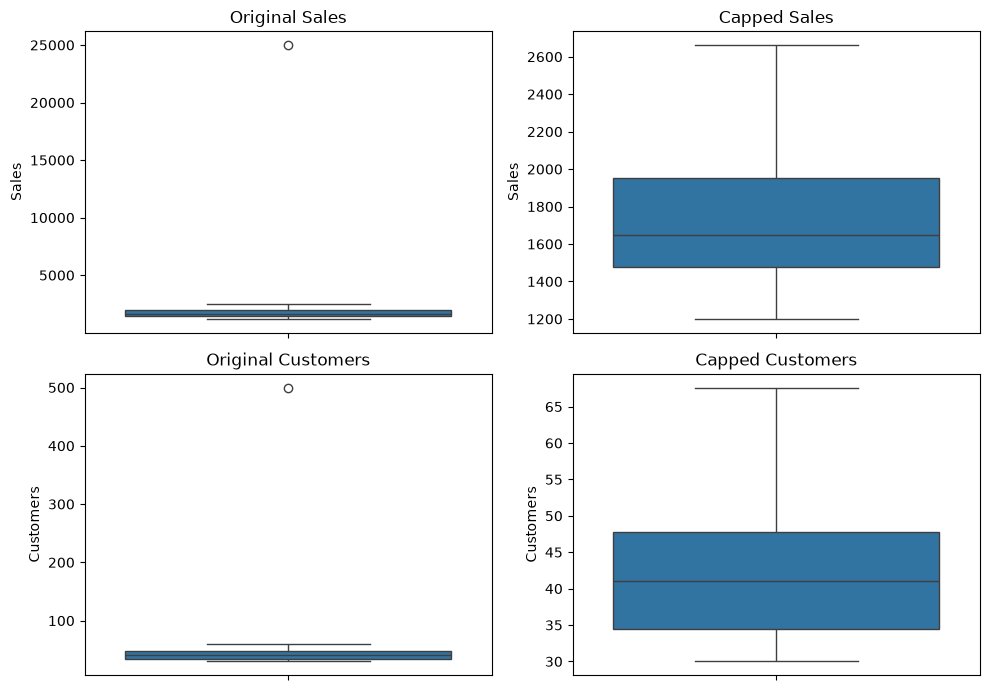

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "Day": range(1, 13),
    "Sales": [1200, 1350, 1400, 1500, 1600, 1550,1700, 1800, 1900, 2100, 2500, 25000],
    "Customers": [30, 32, 35, 33, 38, 40, 42, 45, 47, 50, 60, 500]
})

bounds = {}

for col in ["Sales", "Customers"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    bounds[col] = (lower, upper)

    print(f"\n{col}:")
    print("Q1 =", Q1)
    print("Q3 =", Q3)
    print("IQR =", IQR)
    print("Lower bound =", lower)
    print("Upper bound =", upper)

outlier_mask = pd.Series(False, index=df.index)

for col in ["Sales", "Customers"]:
    lower, upper = bounds[col]
    outlier_mask |= (df[col] < lower) | (df[col] > upper)

removed_df = df.loc[~outlier_mask].copy()
capped_df = df.copy()

for col in ["Sales", "Customers"]:
    lower, upper = bounds[col]
    capped_df[col] = capped_df[col].clip(lower, upper)

print("\nDays removed:")
print(df.loc[outlier_mask].to_string(index=False))

print("\nCapped values:")
print(capped_df.loc[outlier_mask].to_string(index=False))

print("\nRows remaining after removal:", len(removed_df))

fig, axes = plt.subplots(2, 2, figsize=(10, 7))

sns.boxplot(y=df["Sales"], ax=axes[0, 0])
axes[0, 0].set_title("Original Sales")

sns.boxplot(y=capped_df["Sales"], ax=axes[0, 1])
axes[0, 1].set_title("Capped Sales")

sns.boxplot(y=df["Customers"], ax=axes[1, 0])
axes[1, 0].set_title("Original Customers")

sns.boxplot(y=capped_df["Customers"], ax=axes[1, 1])
axes[1, 1].set_title("Capped Customers")

plt.tight_layout()
plt.show()


B. Calculate the correlation between Sales and Customers for the original, removed, and capped datasets. Explain how each technique can change the observed relationship and why a high-sales day should be investigated before being discarded.

In [4]:

import pandas as pd
df = pd.DataFrame({
    "Day": range(1, 13),
    "Sales": [1200, 1350, 1400, 1500, 1600, 1550,
              1700, 1800, 1900, 2100, 2500, 25000],
    "Customers": [30, 32, 35, 33, 38, 40,
                  42, 45, 47, 50, 60, 500]
})

bounds = {}

for col in ["Sales", "Customers"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    bounds[col] = (
        Q1 - 1.5 * IQR,
        Q3 + 1.5 * IQR
    )

outlier_mask = pd.Series(False, index=df.index)

for col in ["Sales", "Customers"]:
    lower, upper = bounds[col]
    outlier_mask |= (df[col] < lower) | (df[col] > upper)

removed_df = df.loc[~outlier_mask].copy()

capped_df = df.copy()

for col in ["Sales", "Customers"]:
    lower, upper = bounds[col]
    capped_df[col] = capped_df[col].clip(lower, upper)

original_corr = df["Sales"].corr(df["Customers"])
removed_corr = removed_df["Sales"].corr(removed_df["Customers"])
capped_corr = capped_df["Sales"].corr(capped_df["Customers"])

comparison = pd.DataFrame({
    "Dataset": ["Original", "Removed", "Capped"],
    "Rows": [len(df), len(removed_df), len(capped_df)],
    "Correlation": [
        original_corr,
        removed_corr,
        capped_corr
    ]
})

print(comparison.round(4).to_string(index=False))


 Dataset  Rows  Correlation
Original    12       0.9999
 Removed    11       0.9847
  Capped    12       0.9892


Question 3: Handling Outliers Without Losing Customer Records

An online platform is analyzing customer spending and order frequency. Every customer record is valuable, so the team wants to evaluate whether capping is preferable to removal.

import pandas as pd

df = pd.DataFrame({
    "Customer_ID": range(101, 113),
    "Annual_Spending": [8000, 10000, 12000, 15000, 18000, 20000,
                        22000, 25000, 30000, 35000, 50000, 800000],
    "Order_Count": [2, 3, 3, 4, 5, 5, 6, 7, 8, 9, 12, 100],
    "Customer_Segment": ["Basic", "Basic", "Silver", "Silver",
                         "Gold", "Basic", "Silver", "Gold",
                         "Gold", "Silver", "Premium", "Premium"]
})
A. Detect outliers in Annual_Spending and Order_Count using the IQR method. Create a removal dataset and a capping dataset while preserving the original DataFrame. Verify that the capped dataset retains every customer and that the removal dataset contains fewer records.



In [5]:

import pandas as pd

df = pd.DataFrame({
    "Customer_ID": range(101, 113),
    "Annual_Spending": [
        8000, 10000, 12000, 15000, 18000, 20000,
        22000, 25000, 30000, 35000, 50000, 800000
    ],
    "Order_Count": [2, 3, 3, 4, 5, 5, 6, 7, 8, 9, 12, 100],
    "Customer_Segment": [
        "Basic", "Basic", "Silver", "Silver",
        "Gold", "Basic", "Silver", "Gold",
        "Gold", "Silver", "Premium", "Premium"
    ]
})

original_df = df.copy(deep=True)
bounds = {}

for col in ["Annual_Spending", "Order_Count"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    bounds[col] = (lower, upper)

    print(f"\n{col}")
    print("Q1 =", Q1)
    print("Q3 =", Q3)
    print("IQR =", IQR)
    print("Lower bound =", lower)
    print("Upper bound =", upper)

outlier_mask = pd.Series(False, index=df.index)

for col in ["Annual_Spending", "Order_Count"]:
    lower, upper = bounds[col]
    outlier_mask |= (df[col] < lower) | (df[col] > upper)

print("\nOutlier customers:")
print(df.loc[outlier_mask].to_string(index=False))

removed_df = df.loc[~outlier_mask].copy()

capped_df = df.copy(deep=True)

for col in ["Annual_Spending", "Order_Count"]:
    lower, upper = bounds[col]
    capped_df[col] = capped_df[col].clip(lower, upper)

print("\nOriginal customer count:", len(original_df))
print("Removal dataset customer count:", len(removed_df))
print("Capping dataset customer count:", len(capped_df))

print("\nOriginal DataFrame remains unchanged:",
      original_df.equals(df))

print("\nCapped dataset:")
print(capped_df.to_string(index=False))

print("\nRemoval dataset:")
print(removed_df.to_string(index=False))



Annual_Spending
Q1 = 14250.0
Q3 = 31250.0
IQR = 17000.0
Lower bound = -11250.0
Upper bound = 56750.0

Order_Count
Q1 = 3.75
Q3 = 8.25
IQR = 4.5
Lower bound = -3.0
Upper bound = 15.0

Outlier customers:
 Customer_ID  Annual_Spending  Order_Count Customer_Segment
         112           800000          100          Premium

Original customer count: 12
Removal dataset customer count: 11
Capping dataset customer count: 12

Original DataFrame remains unchanged: True

Capped dataset:
 Customer_ID  Annual_Spending  Order_Count Customer_Segment
         101             8000            2            Basic
         102            10000            3            Basic
         103            12000            3           Silver
         104            15000            4           Silver
         105            18000            5             Gold
         106            20000            5            Basic
         107            22000            6           Silver
         108            25000        

B. Compare the number of customers in each Customer_Segment before and after removal. Calculate the mean and median spending before and after both treatments. Explain how deleting extreme customers could introduce bias into customer-segment analysis.

In [6]:

import pandas as pd

df = pd.DataFrame({
    "Customer_ID": range(101, 113),
    "Annual_Spending": [
        8000, 10000, 12000, 15000, 18000, 20000,
        22000, 25000, 30000, 35000, 50000, 800000
    ],
    "Order_Count": [2, 3, 3, 4, 5, 5, 6, 7, 8, 9, 12, 100],
    "Customer_Segment": [
        "Basic", "Basic", "Silver", "Silver",
        "Gold", "Basic", "Silver", "Gold",
        "Gold", "Silver", "Premium", "Premium"
    ]
})

bounds = {}

for col in ["Annual_Spending", "Order_Count"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    bounds[col] = (
        Q1 - 1.5 * IQR,
        Q3 + 1.5 * IQR
    )

outlier_mask = pd.Series(False, index=df.index)

for col in ["Annual_Spending", "Order_Count"]:
    lower, upper = bounds[col]
    outlier_mask |= (df[col] < lower) | (df[col] > upper)

removed_df = df.loc[~outlier_mask].copy()
capped_df = df.copy()

for col in ["Annual_Spending", "Order_Count"]:
    lower, upper = bounds[col]
    capped_df[col] = capped_df[col].clip(lower, upper)

segment_counts = pd.DataFrame({
    "Before Removal": df["Customer_Segment"].value_counts(),
    "After Removal": removed_df["Customer_Segment"].value_counts()
}).fillna(0).astype(int)

print("Customer counts by segment:")
print(segment_counts)

datasets = {"Original": df,
           "Removed": removed_df,
           "Capped": capped_df}

results = []

for name, data in datasets.items():
    results.append({
        "Dataset": name,
        "Customer_Count": len(data),
        "Mean_Spending": data["Annual_Spending"].mean(),
        "Median_Spending": data["Annual_Spending"].median()
    })

comparison = pd.DataFrame(results)

print("\nSpending Statistics:")
print(comparison.round(2).to_string(index=False))


Customer counts by segment:
                  Before Removal  After Removal
Customer_Segment                               
Silver                         4              4
Basic                          3              3
Gold                           3              3
Premium                        2              1

Spending Statistics:
 Dataset  Customer_Count  Mean_Spending  Median_Spending
Original              12       87083.33          21000.0
 Removed              11       22272.73          20000.0
  Capped              12       25145.83          21000.0


Question 4: Building a Reusable Outlier Treatment Function
A data science team wants a reusable function that can handle outliers in any selected numerical columns using either removal or capping.

import pandas as pd

df = pd.DataFrame({
    "Product": ["A", "B", "C", "D", "E", "F", "G", "H"],
    "Price": [100, 120, 130, 140, 150, 170, 200, 2000],
    "Delivery_Days": [1, 2, 2, 3, 3, 4, 5, 40],
    "Rating": [3.5, 4.0, 4.2, 4.5, 4.1, 3.8, 4.6, 1.0]
})
A. Write a function that accepts a DataFrame, a list of numerical columns, and a method parameter with options "remove" and "cap". Use IQR boundaries to treat outliers, return the processed DataFrame and a report of the calculated bounds, and ensure the original DataFrame is not modified.




In [7]:

import pandas as pd

df = pd.DataFrame({
    "Product": ["A", "B", "C", "D", "E", "F", "G", "H"],
    "Price": [100, 120, 130, 140, 150, 170, 200, 2000],
    "Delivery_Days": [1, 2, 2, 3, 3, 4, 5, 40],
    "Rating": [3.5, 4.0, 4.2, 4.5, 4.1, 3.8, 4.6, 1.0]
})


def treat_outliers(data, columns, method="cap"):
    if method not in ["remove", "cap"]:
        raise ValueError("Method must be 'remove' or 'cap'.")

    invalid_columns = [col for col in columns if col not in data.columns]
    if invalid_columns:
        raise ValueError(f"Invalid column name(s): {invalid_columns}")

    non_numeric = [
        col for col in columns
        if not pd.api.types.is_numeric_dtype(data[col])
    ]
    if non_numeric:
        raise ValueError(f"Columns must be numerical: {non_numeric}")

    result = data.copy(deep=True)
    report = []
    combined_outlier_mask = pd.Series(False, index=result.index)

    for col in columns:
        Q1 = result[col].quantile(0.25)
        Q3 = result[col].quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        mask = (result[col] < lower) | (result[col] > upper)
        combined_outlier_mask |= mask

        report.append({
            "Column": col,
            "Q1": Q1,
            "Q3": Q3,
            "IQR": IQR,
            "Lower_Bound": lower,
            "Upper_Bound": upper,
            "Outlier_Count": int(mask.sum())
        })

        if method == "cap":
            result[col] = result[col].clip(lower, upper)

    if method == "remove":
        result = result.loc[~combined_outlier_mask].copy()

    report_df = pd.DataFrame(report)
    return result, report_df

cap_df, cap_report = treat_outliers(
    df, ["Price", "Delivery_Days", "Rating"], method="cap"
)

remove_df, remove_report = treat_outliers(
    df, ["Price", "Delivery_Days", "Rating"], method="remove"
)

print("Capping report:")
print(cap_report.round(3).to_string(index=False))

print("\nDataset after capping:")
print(cap_df.to_string(index=False))

print("\nDataset after removal:")
print(remove_df.to_string(index=False))

print("\nOriginal DataFrame unchanged:", 
      df.equals(pd.DataFrame({
          "Product": ["A", "B", "C", "D", "E", "F", "G", "H"],
          "Price": [100, 120, 130, 140, 150, 170, 200, 2000],
          "Delivery_Days": [1, 2, 2, 3, 3, 4, 5, 40],
          "Rating": [3.5, 4.0, 4.2, 4.5, 4.1, 3.8, 4.6, 1.0]
      })))


Capping report:
       Column      Q1      Q3   IQR  Lower_Bound  Upper_Bound  Outlier_Count
        Price 127.500 177.500 50.00       52.500      252.500              1
Delivery_Days   2.000   4.250  2.25       -1.375        7.625              1
       Rating   3.725   4.275  0.55        2.900        5.100              1

Dataset after capping:
Product  Price  Delivery_Days  Rating
      A  100.0          1.000     3.5
      B  120.0          2.000     4.0
      C  130.0          2.000     4.2
      D  140.0          3.000     4.5
      E  150.0          3.000     4.1
      F  170.0          4.000     3.8
      G  200.0          5.000     4.6
      H  252.5          7.625     2.9

Dataset after removal:
Product  Price  Delivery_Days  Rating
      A    100              1     3.5
      B    120              2     4.0
      C    130              2     4.2
      D    140              3     4.5
      E    150              3     4.1
      F    170              4     3.8
      G    200      

B. Apply the function using both methods to all three numerical columns. Compare the row counts, outlier counts, and descriptive statistics. Explain how the function should behave when a column contains no outliers or when the user supplies an invalid column name or method.


In [8]:

import pandas as pd

df = pd.DataFrame({
    "Product": ["A", "B", "C", "D", "E", "F", "G", "H"],
    "Price": [100, 120, 130, 140, 150, 170, 200, 2000],
    "Delivery_Days": [1, 2, 2, 3, 3, 4, 5, 40],
    "Rating": [3.5, 4.0, 4.2, 4.5, 4.1, 3.8, 4.6, 1.0]
})

def treat_outliers(data, columns, method="cap"):
    if method not in ["remove", "cap"]:
        raise ValueError("Method must be 'remove' or 'cap'.")

    invalid = [c for c in columns if c not in data.columns]
    if invalid:
        raise ValueError(f"Invalid column(s): {invalid}")

    non_numeric = [
        c for c in columns
        if not pd.api.types.is_numeric_dtype(data[c])
    ]
    if non_numeric:
        raise ValueError(f"Non-numeric column(s): {non_numeric}")

    result = data.copy(deep=True)
    combined_mask = pd.Series(False, index=data.index)
    report = []

    for col in columns:
        Q1 = data[col].quantile(0.25)
        Q3 = data[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        mask = (data[col] < lower) | (data[col] > upper)
        combined_mask |= mask

        report.append({
            "Column": col,
            "Lower_Bound": lower,
            "Upper_Bound": upper,
            "Outlier_Count": int(mask.sum())
        })

        if method == "cap":
            result[col] = data[col].clip(lower, upper)

    if method == "remove":
        result = result.loc[~combined_mask].copy()

    return result, pd.DataFrame(report)


columns = ["Price", "Delivery_Days", "Rating"]

removed_df, removal_report = treat_outliers(
    df, columns, method="remove"
)

capped_df, capping_report = treat_outliers(
    df, columns, method="cap"
)

print("Removal report:")
print(removal_report.round(3).to_string(index=False))

print("\nCapping report:")
print(capping_report.round(3).to_string(index=False))

print("\nRow counts:")
print("Original:", len(df))
print("Removed:", len(removed_df))
print("Capped:", len(capped_df))

# Descriptive statistics for all three datasets
datasets = {
    "Original": df,
    "Removed": removed_df,
    "Capped": capped_df
}

for name, data in datasets.items():
    print(f"\n{name} dataset statistics:")
    print(
        data[columns].describe()
        .loc[["mean", "50%", "std"]]
        .rename(index={"50%": "median"})
        .round(2)
    )


Removal report:
       Column  Lower_Bound  Upper_Bound  Outlier_Count
        Price       52.500      252.500              1
Delivery_Days       -1.375        7.625              1
       Rating        2.900        5.100              1

Capping report:
       Column  Lower_Bound  Upper_Bound  Outlier_Count
        Price       52.500      252.500              1
Delivery_Days       -1.375        7.625              1
       Rating        2.900        5.100              1

Row counts:
Original: 8
Removed: 7
Capped: 8

Original dataset statistics:
         Price  Delivery_Days  Rating
mean    376.25           7.50    3.71
median  145.00           3.00    4.05
std     656.81          13.19    1.15

Removed dataset statistics:
         Price  Delivery_Days  Rating
mean    144.29           2.86    4.10
median  140.00           3.00    4.10
std      33.09           1.35    0.38

Capped dataset statistics:
         Price  Delivery_Days  Rating
mean    157.81           3.45    3.95
median  145.00